# Retail Orders — Executive Decision Report (Analytics Notebook)
**Domain:** Commerce · **Decision owner:** Sales Manager · **Source:** `retail-orders-raw` sheet of `Retail_KPI_Workbook.xlsx`

This notebook is the full analytical trail behind the executive deck: data audit and cleaning against the data dictionary,
KPI computation (formulas from the `KPI_Dictionary` sheet), revenue drivers, risk areas, three recommendations and ROI scenarios.

In [1]:
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pathlib import Path

XLSX = 'Retail_KPI_Workbook.xlsx'      # keep this file next to the notebook
CHARTS = Path('charts'); CHARTS.mkdir(exist_ok=True)

# --- house style -----------------------------------------------------------
INK, TEAL, AMBER, RED, GREY, LIGHT = '#14213D', '#0F766E', '#D97706', '#B91C1C', '#64748B', '#E2E8F0'
STATUS = {'Paid': TEAL, 'Pending': AMBER, 'Refunded': RED, 'Failed': GREY}
for f in font_manager.findSystemFonts():
    if 'Inter-' in f or 'Inter[' in f: font_manager.fontManager.addfont(f)
plt.rcParams.update({'font.family': ['Inter', 'DejaVu Sans'], 'font.size': 11, 'axes.edgecolor': LIGHT,
    'axes.labelcolor': GREY, 'xtick.color': GREY, 'ytick.color': INK, 'axes.spines.top': False,
    'axes.spines.right': False, 'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlecolor': INK})
inr = lambda x: f"₹{x:,.0f}"

## 1. Load raw data

In [2]:
raw = pd.read_excel(XLSX, sheet_name='retail-orders-raw')
raw.insert(0, 'sheet_row', range(2, len(raw) + 2))
print(raw.shape, '-> 12 records x 9 columns expected by the workbook cover sheet')
raw

(12, 10) -> 12 records x 9 columns expected by the workbook cover sheet


,sheet_row,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,2,RT-1001,2026-01-03 00:00:00,Student,Chennai,Learning Kit,2,799,10.0,Paid
1,3,RT-1002,2026-01-03 00:00:00,Fresher,Bengaluru,Course Access,1,1499,0.0,paid
2,4,RT-1003,2026-01-05 00:00:00,student,Chennai,Course Access,1,1499,NaN,Pending
3,5,RT-1004,2026-01-07 00:00:00,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid
4,6,RT-1004,2026-01-07 00:00:00,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid
5,7,RT-1005,2026-01-09 00:00:00,Fresher,NaN,Mentor Session,1,999,0.0,Failed
6,8,RT-1006,2026-13-10,Student,Pune,Learning Kit,-1,799,10.0,Paid
7,9,RT-1007,2026-01-12 00:00:00,Professional,Mumbai,Mentor Session,2,999,105.0,Paid
8,10,RT-1008,2026-01-14 00:00:00,Fresher,Bengaluru,Course Access,two,1499,0.0,Pending
9,11,RT-1009,2026-01-16 00:00:00,Student,Chennai,Learning Kit,1,799,0.0,Paid


## 2. Data audit & cleaning (rules from the data dictionary)

| Field | Rule applied |
|---|---|
| order_id | Required and unique → exact duplicate removed (first kept) |
| order_date | ISO date between 2025-01-01 and today → invalid / missing dates quarantined |
| customer_segment, payment_status | Trim + title-case normalisation (`student`→`Student`, `paid`→`Paid`) |
| city | Required non-empty → missing city quarantined |
| quantity | Whole number > 0 → word numbers repaired (`two`→2); negatives quarantined |
| discount_pct | 0–100; **missing → 0 only with justification** (see below); >100 quarantined |

*Justification for missing discount (RT-1003):* every other Course Access order at ₹1,499 carries an explicit 0% or a
stated discount, the order is Pending, and no discount-approval record exists, so 0% (list price) is the conservative assumption.
It is flagged and tested in the sensitivity cell.

In [3]:
df = raw.copy()
log = []   # (order_id, sheet_row, issue, action)

# 2a duplicates
dup = df.duplicated('order_id', keep='first')
for _, r in df[dup].iterrows():
    log.append((r.order_id, r.sheet_row, 'Duplicate order_id (exact copy)', 'Removed'))
df = df[~dup].copy()

# 2b normalisation
df['customer_segment'] = df['customer_segment'].str.strip().str.title()
df['payment_status']   = df['payment_status'].str.strip().str.title()
for _, r in raw[raw.customer_segment.ne(raw.customer_segment.str.title()) | raw.payment_status.ne(raw.payment_status.str.title())].iterrows():
    log.append((r.order_id, r.sheet_row, 'Inconsistent text case (segment/status)', 'Normalised'))

# 2c types
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
words = {'one':1,'two':2,'three':3,'four':4,'five':5}
q_in = df['quantity'].copy()
df['quantity'] = pd.to_numeric(df['quantity'].map(lambda v: words.get(str(v).strip().lower(), v)), errors='coerce')
for i in df.index[q_in.astype(str).str.lower().isin(words)]:
    log.append((df.at[i,'order_id'], df.at[i,'sheet_row'], "Quantity typed as text ('two')", 'Repaired to 2'))

df['discount_imputed'] = df['discount_pct'].isna()
for i in df.index[df.discount_imputed]:
    log.append((df.at[i,'order_id'], df.at[i,'sheet_row'], 'Discount missing', 'Set to 0% (justified, flagged)'))
df['discount_pct'] = df['discount_pct'].fillna(0)

# 2d validity rules -> quarantine
today = pd.Timestamp.today().normalize()
def reasons(r):
    out = []
    if pd.isna(r.order_date): out.append('order_date missing/invalid')
    elif not (pd.Timestamp('2025-01-01') <= r.order_date <= today): out.append('order_date out of range')
    if pd.isna(r.city) or str(r.city).strip() == '': out.append('city missing')
    if pd.isna(r.quantity) or r.quantity <= 0 or r.quantity != int(r.quantity): out.append('quantity not a positive whole number')
    if r.unit_price < 0: out.append('unit_price negative')
    if not (0 <= r.discount_pct <= 100): out.append('discount_pct outside 0-100')
    return '; '.join(out)
df['reject_reason'] = df.apply(reasons, axis=1)
quarantine = df[df.reject_reason != ''].copy()
for _, r in quarantine.iterrows():
    log.append((r.order_id, r.sheet_row, r.reject_reason, 'Quarantined (excluded from KPIs)'))

clean = df[df.reject_reason == ''].copy()
clean['quantity'] = clean['quantity'].astype(int)
clean['gross']    = clean.quantity * clean.unit_price
clean['revenue']  = clean.gross * (1 - clean.discount_pct / 100)       # KPI_Dictionary formula
clean['discount_value'] = clean.gross - clean.revenue

issue_log = pd.DataFrame(log, columns=['order_id','sheet_row','issue','action']).sort_values('sheet_row')
print(f"Raw rows: {len(raw)} | duplicates removed: {int(dup.sum())} | quarantined: {len(quarantine)} | clean orders: {len(clean)}")
issue_log

Raw rows: 12 | duplicates removed: 1 | quarantined: 4 | clean orders: 7


,order_id,sheet_row,issue,action
1,RT-1002,3,Inconsistent text case (segment/status),Normalised
2,RT-1003,4,Inconsistent text case (segment/status),Normalised
4,RT-1003,4,Discount missing,"Set to 0% (justified, flagged)"
0,RT-1004,6,Duplicate order_id (exact copy),Removed
5,RT-1005,7,city missing,Quarantined (excluded from KPIs)
6,RT-1006,8,order_date missing/invalid; quantity not a positive whole number,Quarantined (excluded from KPIs)
7,RT-1007,9,discount_pct outside 0-100,Quarantined (excluded from KPIs)
3,RT-1008,10,Quantity typed as text ('two'),Repaired to 2
8,RT-1011,13,order_date missing/invalid,Quarantined (excluded from KPIs)


In [4]:
clean[['order_id','order_date','customer_segment','city','category','quantity','unit_price','discount_pct','payment_status','revenue']]

,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,revenue
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid,1438.20
1,RT-1002,2026-01-03,Fresher,Bengaluru,Course Access,1,1499,0.0,Paid,1499.00
2,RT-1003,2026-01-05,Student,Chennai,Course Access,1,1499,0.0,Pending,1499.00
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid,2277.15
8,RT-1008,2026-01-14,Fresher,Bengaluru,Course Access,2,1499,0.0,Pending,2998.00
9,RT-1009,2026-01-16,Student,Chennai,Learning Kit,1,799,0.0,Paid,799.00
10,RT-1010,2026-01-18,Professional,Delhi,Course Access,2,1499,15.0,Refunded,2548.30


## 3. KPI scorecard (formulas from `KPI_Dictionary`)

In [5]:
paid = clean[clean.payment_status == 'Paid']; pend = clean[clean.payment_status == 'Pending']; refd = clean[clean.payment_status == 'Refunded']
K = dict(
    total_revenue = clean.revenue.sum(),
    total_orders  = clean.order_id.nunique(),
    total_qty     = int(clean.quantity.sum()),
    avg_discount  = clean.discount_pct.mean(),
    paid_orders   = len(paid), pending_orders = len(pend), refunded_orders = len(refd),
)
K['aov'] = K['total_revenue'] / K['total_orders']
K['pay_success'] = K['paid_orders'] / K['total_orders'] * 100
K['paid_rev'], K['pend_rev'], K['ref_rev'] = paid.revenue.sum(), pend.revenue.sum(), refd.revenue.sum()
K['realization'] = K['paid_rev'] / K['total_revenue'] * 100
K['discount_given'] = clean.discount_value.sum()
K['span_days'] = (clean.order_date.max() - clean.order_date.min()).days + 1
K['raw_rows'], K['usable_share'] = len(raw), len(clean) / len(raw) * 100

scorecard = pd.DataFrame([
    ('Total Revenue (booked, after discount)', inr(K['total_revenue'])),
    ('Total Orders (distinct)', K['total_orders']),
    ('Average Order Value', inr(K['aov'])),
    ('Total Quantity Sold', K['total_qty']),
    ('Average Discount', f"{K['avg_discount']:.1f}%"),
    ('Paid Orders', K['paid_orders']),
    ('Pending Orders', K['pending_orders']),
    ('Payment Success Rate', f"{K['pay_success']:.1f}%"),
    ('Collected revenue (Paid only)', inr(K['paid_rev'])),
    ('Revenue realisation (Paid / booked)', f"{K['realization']:.1f}%"),
], columns=['KPI','Value'])
scorecard

,KPI,Value
0,"Total Revenue (booked, after discount)","₹13,059"
1,Total Orders (distinct),7
2,Average Order Value,"₹1,866"
3,Total Quantity Sold,12
4,Average Discount,4.3%
5,Paid Orders,4
6,Pending Orders,2
7,Payment Success Rate,57.1%
8,Collected revenue (Paid only),"₹6,013"
9,Revenue realisation (Paid / booked),46.0%


## 4. Revenue drivers

In [6]:
def pivot(by):
    p = clean.pivot_table(index=by, columns='payment_status', values='revenue', aggfunc='sum', fill_value=0)
    for s in ['Paid','Pending','Refunded']:
        if s not in p: p[s] = 0
    p['Total'] = p[['Paid','Pending','Refunded']].sum(axis=1)
    p['Orders'] = clean.groupby(by).order_id.nunique()
    p['Share_%'] = p.Total / p.Total.sum() * 100
    p['Collected_%'] = p.Paid / p.Total * 100
    return p.sort_values('Total', ascending=False)

by_cat, by_seg, by_city = pivot('category'), pivot('customer_segment'), pivot('city')
by_cat

payment_status,Paid,Pending,Refunded,Total,Orders,Share_%,Collected_%
category,,,,,,,
Course Access,1499.00,4497.0,2548.3,8544.30,4,65.430194,17.54386
Learning Kit,4514.35,0.0,0.0,4514.35,3,34.569806,100.00000


In [7]:
by_seg

payment_status,Paid,Pending,Refunded,Total,Orders,Share_%,Collected_%
customer_segment,,,,,,,
Professional,2277.15,0.0,2548.3,4825.45,2,36.952135,47.190417
Fresher,1499.00,2998.0,0.0,4497.00,2,34.436944,33.333333
Student,2237.20,1499.0,0.0,3736.20,3,28.610921,59.879021


In [8]:
by_city

payment_status,Paid,Pending,Refunded,Total,Orders,Share_%,Collected_%
city,,,,,,,
Bengaluru,1499.00,2998.0,0.0,4497.00,2,34.436944,33.333333
Chennai,2237.20,1499.0,0.0,3736.20,3,28.610921,59.879021
Delhi,0.00,0.0,2548.3,2548.30,1,19.514268,0.000000
Hyderabad,2277.15,0.0,0.0,2277.15,1,17.437867,100.000000


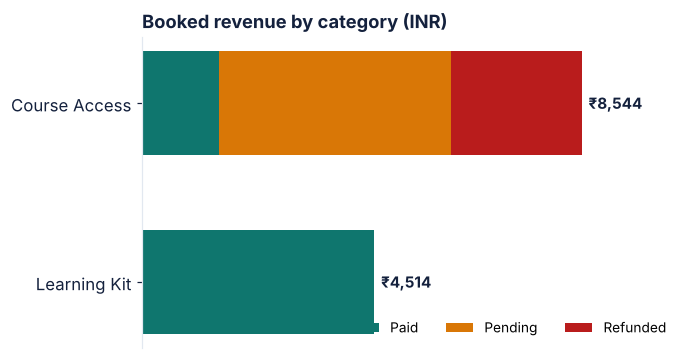

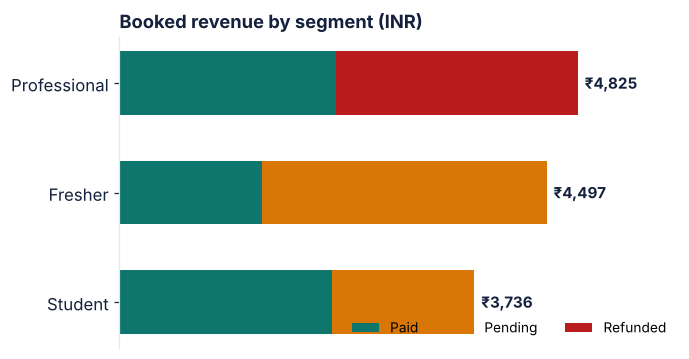

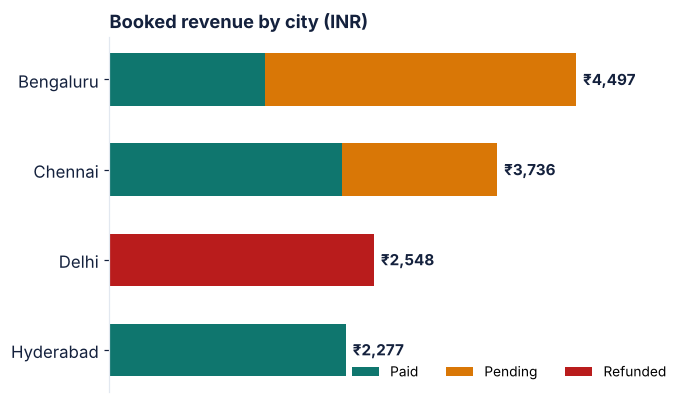

In [9]:
def stacked_h(p, title, fname, size=(6.4, 3.4)):
    fig, ax = plt.subplots(figsize=size)
    p = p.iloc[::-1]; left = np.zeros(len(p))
    for s in ['Paid','Pending','Refunded']:
        ax.barh(p.index, p[s], left=left, color=STATUS[s], label=s, height=0.58)
        left += p[s].values
    for y, t in enumerate(p.Total):
        ax.text(t + p.Total.max()*0.015, y, inr(t), va='center', color=INK, fontsize=10, fontweight='bold')
    ax.set_xlim(0, p.Total.max()*1.22); ax.xaxis.set_visible(False); ax.spines['bottom'].set_visible(False)
    ax.set_title(title, loc='left', fontsize=12); ax.legend(frameon=False, ncol=3, loc='lower right', fontsize=9)
    fig.tight_layout(); fig.savefig(CHARTS/fname, dpi=220, transparent=False, facecolor='white'); plt.show()
stacked_h(by_cat, 'Booked revenue by category (INR)', 'cat.png')
stacked_h(by_seg, 'Booked revenue by segment (INR)', 'seg.png')
stacked_h(by_city, 'Booked revenue by city (INR)', 'city.png', size=(6.4, 3.8))

## 5. Payment health & risk areas

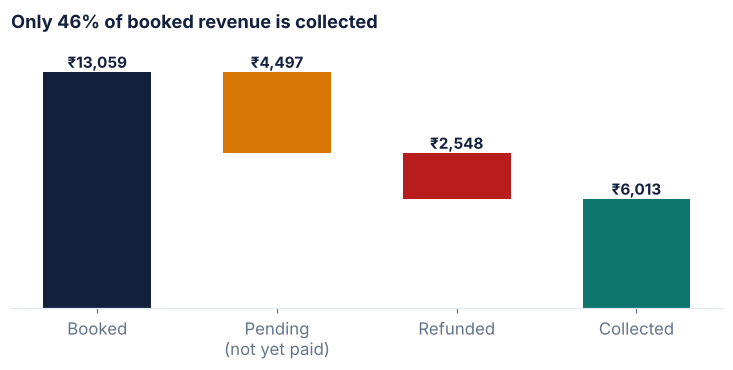

In [10]:
# Booked -> collected bridge
fig, ax = plt.subplots(figsize=(6.8, 3.5))
steps = [('Booked', K['total_revenue'], INK), ('Pending\n(not yet paid)', -K['pend_rev'], AMBER),
         ('Refunded', -K['ref_rev'], RED), ('Collected', K['paid_rev'], TEAL)]
run = 0
for i, (lab, v, c) in enumerate(steps):
    if lab in ('Booked', 'Collected'):
        ax.bar(i, v, color=c, width=.6); run = v if lab == 'Booked' else run; top = v
    else:
        ax.bar(i, -v, bottom=run + v, color=c, width=.6); run += v; top = run - v
    ax.text(i, (top if lab in ('Booked','Collected') else run - v) + K['total_revenue']*0.02, inr(abs(v)),
            ha='center', fontweight='bold', color=INK, fontsize=10)
ax.set_xticks(range(4)); ax.set_xticklabels([s[0] for s in steps]); ax.yaxis.set_visible(False)
ax.spines['left'].set_visible(False); ax.set_ylim(0, K['total_revenue']*1.15)
ax.set_title(f"Only {K['realization']:.0f}% of booked revenue is collected", loc='left', fontsize=12)
fig.tight_layout(); fig.savefig(CHARTS/'bridge.png', dpi=220, facecolor='white'); plt.show()

In [11]:
# Risk metrics
risk = {}
risk['pend_share']  = K['pend_rev'] / K['total_revenue'] * 100
risk['ref_share']   = K['ref_rev']  / K['total_revenue'] * 100
risk['cat_pend_ref_share'] = clean[clean.payment_status.isin(['Pending','Refunded'])].query("category=='Course Access'").revenue.sum() / \
                             clean[clean.payment_status.isin(['Pending','Refunded'])].revenue.sum() * 100
risk['top_cat_share'] = by_cat['Share_%'].iloc[0]; risk['top_cat'] = by_cat.index[0]
risk['top_city_share'] = by_city['Share_%'].iloc[0]; risk['top_city'] = by_city.index[0]
risk['n_cities'] = clean.city.nunique()
# Data-quality exposure: value of quarantined rows at list price (what we cannot see)
q = quarantine.copy(); q['qty_abs'] = pd.to_numeric(q.quantity, errors='coerce').abs()
risk['quarantined_list_value'] = (q.qty_abs * q.unit_price).sum()
risk['mentor_orders_raw'] = int((raw.category == 'Mentor Session').sum())
risk['mentor_orders_clean'] = int((clean.category == 'Mentor Session').sum())
risk['dq_rejects'] = len(raw) - len(clean)
# Discounted orders: collection quality
risk['disc_orders'] = int((clean.discount_pct > 0).sum())
risk['avg_disc_refunded'] = float(refd.discount_pct.mean()) if len(refd) else 0
risk

{'pend_share': np.float64(34.436944094527384), 'ref_share': np.float64(19.51426832023218), 'cat_pend_ref_share': np.float64(100.0), 'top_cat_share': np.float64(65.43019377960202), 'top_cat': 'Course Access', 'top_city_share': np.float64(34.436944094527384), 'top_city': 'Bengaluru', 'n_cities': 4, 'quarantined_list_value': np.int64(4795), 'mentor_orders_raw': 3, 'mentor_orders_clean': 0, 'dq_rejects': 5, 'disc_orders': 3, 'avg_disc_refunded': 15.0}

## 6. Recommendations & ROI projections

Three recommendations, each tied to a finding above. **ROI inputs are planning assumptions** (cost lines are placeholders to be replaced with real quotes).
Revenue is extrapolated from the observed sample run-rate (booked revenue per day × 365) — the sample is only 7 clean orders over 16 days, so treat as *directional*.

In [12]:
PARAMS = dict(
    # lever: (conservative, base, upside) assumption and one-time + first-year cost in INR
    pay_recovery  = (0.25, 0.50, 0.75),   # share of Pending revenue recovered
    dq_recovery   = (0.10, 0.25, 0.40),   # share of quarantined list value that becomes valid, collectable revenue
    bundle_attach = (0.10, 0.25, 0.40),   # share of Course Access orders adding a Learning Kit
)
COST = dict(pay_recovery=12000, dq_recovery=15000, bundle_attach=8000)

days = K['span_days']; annual = lambda x: x / days * 365
kit_price = clean.loc[clean.category == 'Learning Kit', 'unit_price'].iloc[0]
n_course = int((clean.category == 'Course Access').sum())
kit_net = kit_price * (1 - clean.loc[clean.category == 'Learning Kit', 'discount_pct'].mean() / 100)

rows = []
for i, sc in enumerate(['Conservative', 'Base', 'Upside']):
    g = dict(
        pay_recovery  = annual(K['pend_rev'] * PARAMS['pay_recovery'][i]),
        dq_recovery   = annual(risk['quarantined_list_value'] * PARAMS['dq_recovery'][i]),
        bundle_attach = annual(n_course * PARAMS['bundle_attach'][i] * kit_net),
    )
    for k, v in g.items(): rows.append((sc, k, v, COST[k], (v - COST[k]) / COST[k] * 100))
roi = pd.DataFrame(rows, columns=['scenario','lever','annual_gain','cost','roi_pct'])
roi_tot = roi.groupby('scenario').agg(annual_gain=('annual_gain','sum'), cost=('cost','sum'))
roi_tot['roi_pct'] = (roi_tot.annual_gain - roi_tot.cost) / roi_tot.cost * 100
roi_tot['payback_months'] = roi_tot.cost / (roi_tot.annual_gain / 12)
roi_tot = roi_tot.loc[['Conservative','Base','Upside']]
K['annual_run_rate'] = annual(K['total_revenue'])
print('Annualised booked run-rate:', inr(K['annual_run_rate']))
roi_tot.round(1)

Annualised booked run-rate: ₹297,900


,annual_gain,cost,roi_pct,payback_months
scenario,,,,
Conservative,43511.9,35000,24.3,9.7
Base,95956.2,35000,174.2,4.4
Upside,148400.6,35000,324.0,2.8


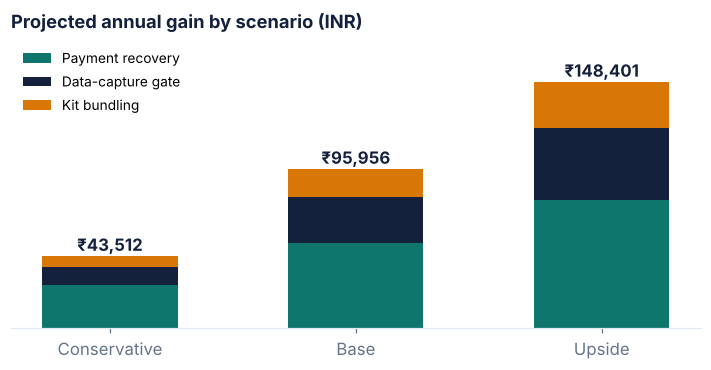

scenario,Conservative,Base,Upside
lever,,,
pay_recovery,25647.0,51294.0,76941.0
dq_recovery,10939.0,27346.0,43754.0
bundle_attach,6926.0,17316.0,27705.0


In [13]:
roi_lever = roi.pivot(index='lever', columns='scenario', values='annual_gain').loc[['pay_recovery','dq_recovery','bundle_attach'], ['Conservative','Base','Upside']]
fig, ax = plt.subplots(figsize=(6.6, 3.5))
cols = {'pay_recovery': TEAL, 'dq_recovery': INK, 'bundle_attach': AMBER}
names = {'pay_recovery': 'Payment recovery', 'dq_recovery': 'Data-capture gate', 'bundle_attach': 'Kit bundling'}
bottom = np.zeros(3)
for lv in roi_lever.index:
    ax.bar(roi_lever.columns, roi_lever.loc[lv], bottom=bottom, color=cols[lv], label=names[lv], width=.55); bottom += roi_lever.loc[lv].values
for i, t in enumerate(bottom): ax.text(i, t + bottom.max()*.02, inr(t), ha='center', fontweight='bold', color=INK)
ax.yaxis.set_visible(False); ax.spines['left'].set_visible(False); ax.set_ylim(0, bottom.max()*1.18)
ax.legend(frameon=False, fontsize=9, loc='upper left'); ax.set_title('Projected annual gain by scenario (INR)', loc='left', fontsize=12)
fig.tight_layout(); fig.savefig(CHARTS/'roi.png', dpi=220, facecolor='white'); plt.show()
roi_lever.round(0)

## 7. Sensitivity: does the missing-discount assumption change the story?

In [14]:
alt = clean.copy(); alt.loc[alt.discount_imputed, 'discount_pct'] = 15   # worst case: highest observed discount
alt['revenue'] = alt.quantity * alt.unit_price * (1 - alt.discount_pct / 100)
print('Booked revenue, 0% assumption :', inr(K['total_revenue']))
print('Booked revenue, 15% assumption:', inr(alt.revenue.sum()), f"(Δ {inr(alt.revenue.sum()-K['total_revenue'])})")
print('Pending revenue changes by only', inr(K['pend_rev'] - alt[alt.payment_status=='Pending'].revenue.sum()), '— conclusions unchanged.')

Booked revenue, 0% assumption : ₹13,059
Booked revenue, 15% assumption: ₹12,834 (Δ ₹-225)
Pending revenue changes by only ₹225 — conclusions unchanged.
